In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf

In [3]:
PROJECT_ROOT = Path("/Users/yaasarpong/Desktop/PHD/Year 4 fall/finance-volatility")

In [4]:
DATA_DIR = PROJECT_ROOT /"data"
RESULTS_DIR = PROJECT_ROOT /"results"
FIGURES_DIR = PROJECT_ROOT /"figures"

In [5]:
RESULTS_DIR.mkdir(parents=True,exist_ok=True)
FIGURES_DIR.mkdir(parents=True,exist_ok=True)

In [6]:
def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(
        FIGURES_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close(fig)

In [7]:
#load the raw data and create predictors

In [8]:
data = pd.read_csv(DATA_DIR / "financial_raw_data.csv",
    parse_dates=["date"])

In [9]:
assert data["date"].notna().all(), "Missing dates found."
assert not data["date"].duplicated().any(), "Duplicate dates found."

In [10]:
# Keep 2025 out of this analysis.
data = (data.loc[data["date"] <= pd.Timestamp("2024-12-31")]
    .sort_values("date")
    .reset_index(drop=True))

In [11]:
base_columns = ["sp500", "vix", "treasury_10yr"]

for column in base_columns:
    data[column] = pd.to_numeric(data[column], errors="raise")

assert not np.isinf(data[base_columns].to_numpy()).any(), ("Infinite values found.")

In [12]:
# Preserve all observed S&P 500 dates.
data = data.dropna(subset=["sp500"]).reset_index(drop=True)

assert data["sp500"].gt(0).all(), "S&P 500 levels must be positive."

In [13]:
# Returns and return-history predictors.
data["log_return"] = 100 * np.log(data["sp500"]).diff()
data["absolute_return"] = data["log_return"].abs()

data["mean_abs_5"] = (data["absolute_return"].rolling(5, min_periods=5).mean())

data["mean_abs_20"] = (data["absolute_return"].rolling(20, min_periods=20).mean())

In [14]:
# Yield change in percentage points.
# A missing yield on either adjacent S&P observation produces NaN.
data["treasury_change"] = data["treasury_10yr"].diff()

In [15]:
# Tomorrow's outcome and its date.
data["target_next_day"] = data["absolute_return"].shift(-1)
data["target_date"] = data["date"].shift(-1)

In [16]:
# Recreate the Day 11 baselines on this same sequence.
data["historical_mean"] = (data["absolute_return"].expanding(min_periods=20).mean())

In [17]:
data["ewm_20"] = (data["absolute_return"]
    .ewm(span=20, adjust=False, min_periods=20).mean())

In [18]:
display(data[["date", "absolute_return", "mean_abs_5",
            "mean_abs_20", "target_date", "target_next_day"]].head(25))

,date,absolute_return,mean_abs_5,mean_abs_20,target_date,target_next_day
0,2016-10-03,NaN,NaN,NaN,2016-10-04,0.496790
1,2016-10-04,0.496790,NaN,NaN,2016-10-05,0.428749
2,2016-10-05,0.428749,NaN,NaN,2016-10-06,0.048143
3,2016-10-06,0.048143,NaN,NaN,2016-10-07,0.325877
4,2016-10-07,0.325877,NaN,NaN,2016-10-10,0.459537
5,2016-10-10,0.459537,0.351819,NaN,2016-10-11,1.252461
6,2016-10-11,1.252461,0.502953,NaN,2016-10-12,0.114596
7,2016-10-12,0.114596,0.440123,NaN,2016-10-13,0.310413
8,2016-10-13,0.310413,0.492577,NaN,2016-10-14,0.020162
9,2016-10-14,0.020162,0.431434,NaN,2016-10-17,0.304263


In [19]:
# create the training and validation samples

In [20]:
history_features = ["absolute_return","mean_abs_5","mean_abs_20",]

In [21]:
extended_features = history_features + ["vix","treasury_change",]

In [22]:
baseline_columns = ["historical_mean", "ewm_20"]

In [23]:
required_columns = [*extended_features,*baseline_columns,
    "target_next_day","target_date",]

In [24]:
usable = data.dropna(subset=required_columns).copy()

In [25]:
train = usable.loc[usable["target_date"] <= pd.Timestamp("2022-12-31")].copy()

In [26]:
validation = usable.loc[usable["target_date"].between(
        pd.Timestamp("2023-01-01"),
        pd.Timestamp("2024-12-31"))].copy()

In [27]:
assert len(train) > 30, "Too few training observations."
assert not validation.empty, "No validation observations."

In [28]:
for frame in [train, validation]:
    assert (frame["date"] < frame["target_date"]).all()
    assert np.isfinite(
        frame[
            extended_features
            + baseline_columns
            + ["target_next_day"]
        ].to_numpy()
    ).all()

In [29]:
for name, frame in [("Training", train), ("Validation", validation)]:
    print(
        name,
        "| Rows:", len(frame),
        "| Target dates:",
        frame["target_date"].min().date(),
        "to",
        frame["target_date"].max().date()
    )

Training | Rows: 1528 | Target dates: 2016-11-01 to 2022-12-30
Validation | Rows: 496 | Target dates: 2023-01-03 to 2024-12-31


In [30]:
# fit the two regression models

In [31]:
feature_sets = {"history_regression": history_features,
    "extended_regression": extended_features,}

models = {}

for name, features in feature_sets.items():
    X_train = sm.add_constant(train[features],has_constant="add")

    models[name] = sm.OLS(
        train["target_next_day"],X_train,missing="raise").fit()

    print(f"\n{name}")
    print(models[name].summary())

    (RESULTS_DIR / f"day12_{name}_summary.txt").write_text(
        models[name].summary().as_text(),
        encoding="utf-8")


history_regression
                            OLS Regression Results                            
Dep. Variable:        target_next_day   R-squared:                       0.340
Model:                            OLS   Adj. R-squared:                  0.338
Method:                 Least Squares   F-statistic:                     261.4
Date:                Fri, 02 Oct 2026   Prob (F-statistic):          7.70e-137
Time:                        18:37:14   Log-Likelihood:                -1831.2
No. Observations:                1528   AIC:                             3670.
Df Residuals:                    1524   BIC:                             3692.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.

In [32]:
# generate forecasts and calculate performance

In [33]:
predictions = validation[
    ["date","target_date","target_next_day",*baseline_columns,]].copy()

In [34]:
for name, features in feature_sets.items():
    X_validation = sm.add_constant(
        validation[features],
        has_constant="add"
    )

    predictions[name] = models[name].predict(X_validation)

In [35]:
methods = baseline_columns + list(feature_sets)

In [36]:
assert np.isfinite(predictions[methods].to_numpy()).all()

In [37]:
# Check whether the regressions produce impossible negative magnitudes.
negative_counts = (
    predictions[list(feature_sets)] < 0
).sum()

print("Negative regression forecasts:")
display(negative_counts)

Negative regression forecasts:


history_regression     0
extended_regression    0
dtype: int64

In [38]:
scores = []

for method in methods:
    error = predictions[method] - predictions["target_next_day"]

    scores.append({"method": method,
        "n_forecasts": len(error),
        "MAE": error.abs().mean(),
        "RMSE": np.sqrt((error ** 2).mean()),
        "Bias": error.mean(),})

performance = (pd.DataFrame(scores)
    .set_index("method")
    .sort_values("MAE"))

In [39]:
# Positive values mean improvement relative to EWM.
for metric in ["MAE", "RMSE"]:
    reference = performance.loc["ewm_20", metric]

    performance[f"{metric}_improvement_vs_ewm_pct"] = (
        100 * (1 - performance[metric] / reference)
    )

display(performance.round(4))

print("Lowest MAE:", performance["MAE"].idxmin())
print("Lowest RMSE:", performance["RMSE"].idxmin())

,n_forecasts,MAE,RMSE,Bias,MAE_improvement_vs_ewm_pct,RMSE_improvement_vs_ewm_pct
method,,,,,,
extended_regression,496,0.4153,0.5261,-0.0325,1.7998,0.7532
ewm_20,496,0.4229,0.5301,0.0037,0.0000,0.0000
history_regression,496,0.4318,0.5375,0.0306,-2.1111,-1.3893
historical_mean,496,0.4591,0.5471,0.1425,-8.5576,-3.2057


Lowest MAE: extended_regression
Lowest RMSE: extended_regression


In [40]:
#examine training residuals and predictor correlations

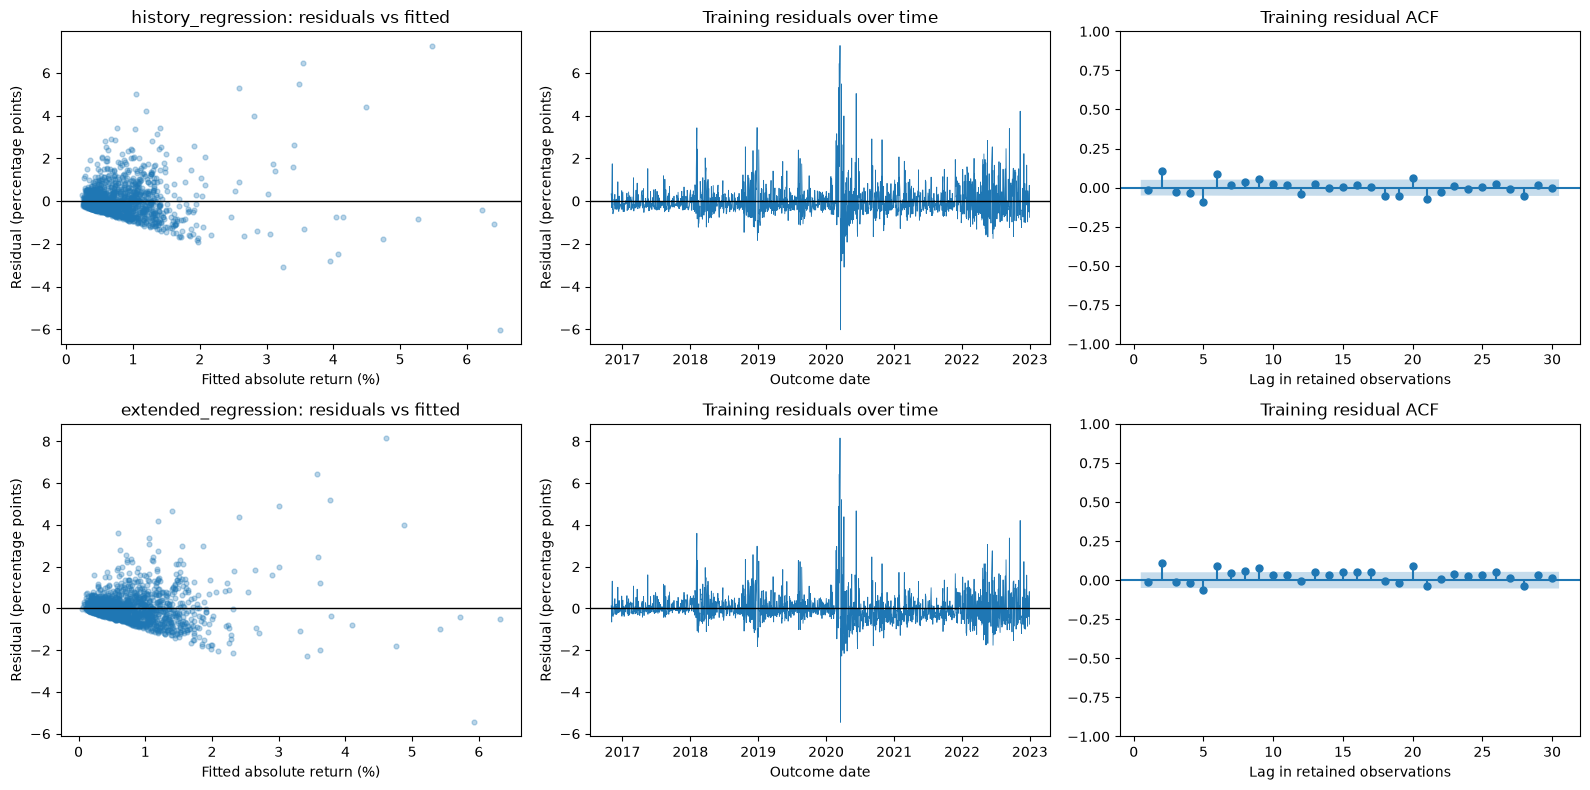

,absolute_return,mean_abs_5,mean_abs_20,vix,treasury_change
absolute_return,1.000,0.742,0.570,0.660,-0.049
mean_abs_5,0.742,1.000,0.815,0.857,0.001
mean_abs_20,0.570,0.815,1.000,0.845,-0.008
vix,0.660,0.857,0.845,1.000,-0.028
treasury_change,-0.049,0.001,-0.008,-0.028,1.000


In [41]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for row, (name, model) in enumerate(models.items()):
    residuals = model.resid

    axes[row, 0].scatter(
        model.fittedvalues,
        residuals,
        alpha=0.3,
        s=12
    )
    axes[row, 0].axhline(0, color="black", linewidth=1)
    axes[row, 0].set_title(f"{name}: residuals vs fitted")
    axes[row, 0].set_xlabel("Fitted absolute return (%)")
    axes[row, 0].set_ylabel("Residual (percentage points)")

    axes[row, 1].plot(
        train["target_date"],
        residuals,
        linewidth=0.6
    )
    axes[row, 1].axhline(0, color="black", linewidth=1)
    axes[row, 1].set_title("Training residuals over time")
    axes[row, 1].set_xlabel("Outcome date")
    axes[row, 1].set_ylabel("Residual (percentage points)")

    plot_acf(
        residuals.to_numpy(),
        lags=30,
        zero=False,
        missing="raise",
        ax=axes[row, 2]
    )
    axes[row, 2].set_title("Training residual ACF")
    axes[row, 2].set_xlabel("Lag in retained observations")

save_figure(fig, "day12_training_diagnostics.png")

predictor_correlations = train[extended_features].corr()

display(predictor_correlations.round(3))

In [42]:
#plot and save your validation results

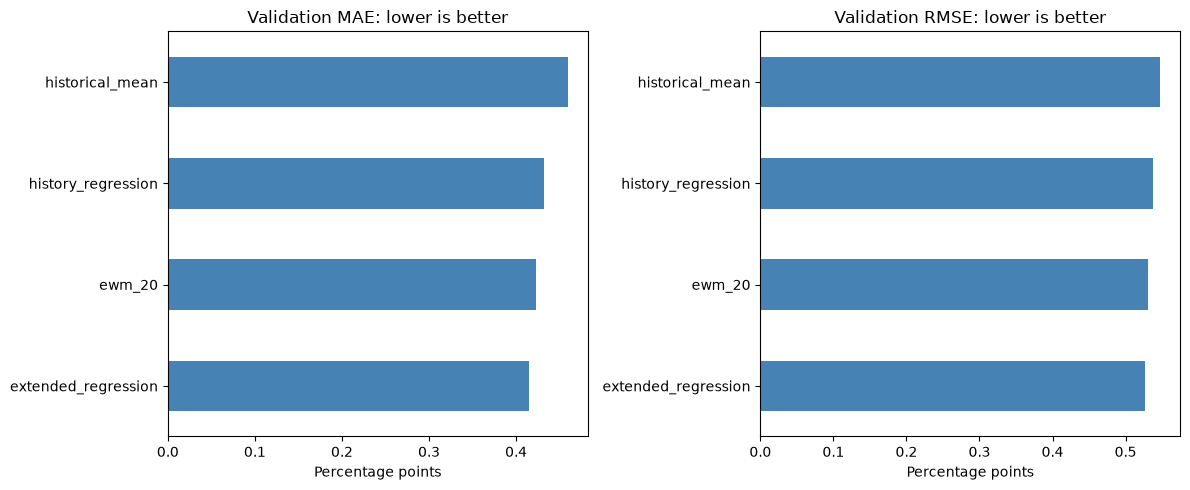

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric in zip(axes, ["MAE", "RMSE"]):
    performance[metric].sort_values().plot(
        kind="barh",
        ax=ax,
        color="steelblue"
    )
    ax.set_title(f"Validation {metric}: lower is better")
    ax.set_xlabel("Percentage points")
    ax.set_ylabel("")

save_figure(fig, "day12_model_comparison.png")

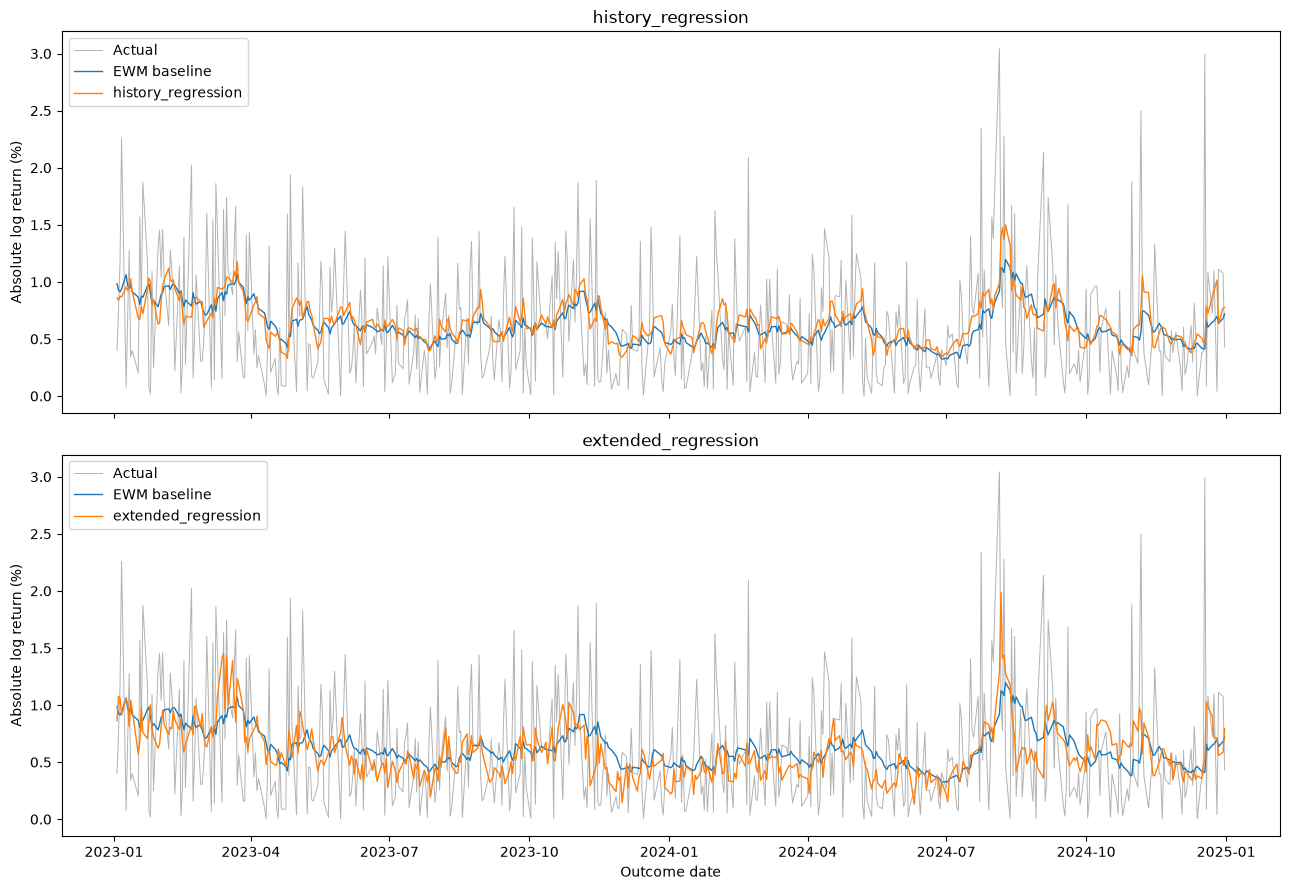

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, name in zip(axes, feature_sets):
    ax.plot(
        predictions["target_date"],
        predictions["target_next_day"],
        label="Actual",
        color="gray",
        linewidth=0.7,
        alpha=0.6
    )

    ax.plot(
        predictions["target_date"],
        predictions["ewm_20"],
        label="EWM baseline",
        linewidth=1
    )

    ax.plot(
        predictions["target_date"],
        predictions[name],
        label=name,
        linewidth=1
    )

    ax.set_title(name)
    ax.set_ylabel("Absolute log return (%)")
    ax.legend()

axes[-1].set_xlabel("Outcome date")

save_figure(fig, "day12_validation_forecasts.png")

In [45]:
predictions.to_csv(
    RESULTS_DIR / "day12_validation_predictions.csv",
    index=False
)

performance.to_csv(
    RESULTS_DIR / "day12_model_performance.csv"
)

predictor_correlations.to_csv(
    RESULTS_DIR / "day12_predictor_correlations.csv"
)

print("Day 12 results saved.")

Day 12 results saved.


**Your extended regression performed best on validation MAE and RMSE, but its improvement over EWM is modest.** The diagnostic plots also show that some important error patterns remain unexplained.

Here is what your results tell us.

**1. Adding VIX and Treasury changes improved validation performance**

All four methods were evaluated on the same **496 forecast dates**:

| Method | MAE | RMSE | Bias |
|---|---:|---:|---:|
| **Extended regression** | **0.4153** | **0.5261** | −0.0325 |
| EWM baseline | 0.4229 | 0.5301 | 0.0037 |
| Return-history regression | 0.4318 | 0.5375 | 0.0306 |
| Historical mean | 0.4591 | 0.5471 | 0.1425 |

These errors are in **percentage points**.

Compared with EWM, the extended regression reduced:

- **MAE by 1.80%**
- **RMSE by 0.75%**

This supports retaining the extended model for further evaluation. **It does not yet establish a statistically reliable advantage**, because the differences are small and you have not quantified their uncertainty.

The return-history regression did **not** beat EWM. Estimating regression weights for recent returns therefore did not improve forecasting by itself in this validation period.

**2. EWM had the smallest average bias**

The extended regression’s bias of **−0.0325** means it underpredicted absolute returns by about **0.033 percentage points on average**.

EWM’s bias was closer to zero, at **0.0037**. That does not contradict the extended model’s lower MAE and RMSE: average bias and individual forecast accuracy measure different things.

The historical mean noticeably overpredicted, with bias **0.1425**.

**3. The fitted coefficients show how the predictors work together**

Training \(R^2\) increased from **0.340 to 0.381** when you added VIX and Treasury changes. That describes training fit; the validation table provides the forecasting comparison.

In the extended model:

| Predictor | Coefficient | Interpretation, holding the other predictors fixed |
|---|---:|---|
| VIX | 0.0487 | A one-point higher VIX corresponds to a 0.0487-percentage-point higher predicted absolute return. |
| Treasury-yield change | −1.2529 | A yield increase of 0.10 percentage points corresponds to a 0.1253-percentage-point lower prediction. |
| 5-day mean absolute return | 0.4048 | Higher recent return magnitudes correspond to higher predicted movement. |

These are **conditional associations, not causal effects**.

Also, adding VIX and Treasury changes **together** improved performance. This comparison cannot tell you how much each variable contributed separately.

**4. Several predictors contain overlapping information**

Your correlation table shows:

- VIX and the 5-day mean: **0.857**
- VIX and the 20-day mean: **0.845**
- The 5-day and 20-day means: **0.815**

This helps explain why the 20-day mean’s coefficient changes from positive in the history model to negative in the extended model. Once VIX and the other predictors are included, its coefficient measures its *additional* association.

**Do not interpret that negative coefficient as evidence that higher recent volatility generally predicts lower future volatility.**

**5. The residual diagnostics reveal remaining limitations**

Your plots show:

- **Changing error spread:** Large residuals cluster around 2020, with elevated errors again during 2022. Constant error variance looks questionable.
- **Strong asymmetry and extreme residuals:** Residual skewness is approximately **2.01 and 2.26**, with kurtosis **17.90 and 20.71**. Normal errors would have kurtosis 3.
- **Remaining temporal dependence:** Several residual ACF spikes extend outside the approximate bands. Durbin–Watson values near 2 do not establish independence at all lags.

The sloping lower boundary in the residual-versus-fitted plots is partly mechanical: actual absolute returns cannot fall below zero, so residuals cannot fall below minus the fitted value.

Your summaries use **nonrobust standard errors**. Given these diagnostics, avoid making strong claims from their reported p-values.

**6. The forecasts capture broad changes better than individual spikes**

Both regression models follow periods of lower and higher movement, while missing many individual large returns. The extended model reacts more sharply in some periods, particularly around August 2024.

That is consistent with predicting an expected movement magnitude: the forecast need not reproduce every realized spike.

Your displayed split is also consistent with the intended setup:

| Sample | Observations | Outcome dates |
|---|---:|---|
| Training | 1,528 | November 1, 2016–December 30, 2022 |
| Validation | 496 | January 3, 2023–December 31, 2024 |

Use the **new EWM scores above**, rather than its Day 11 scores based on 502 dates.

**For Day 12, retain the extended regression as your current validation leader and EWM as the main benchmark.** Record these findings, confirm the negative-forecast count from your earlier cell, and keep **2025 untouched**. Once your outputs and interpretation are saved, Day 12 is complete.

**Day 19 of 30 — Rewrite your resume for quantitative research**

Today, build a focused resume that leads with your statistical training and research projects.

- [ ] **Reorder sections:** Education → Research & Projects → Technical Skills → Relevant Experience.
- [ ] **Lead with your Python financial forecasting project.** Describe the prediction target, time-based validation, regression models, and EWM benchmark. Label it **in progress**; your latest completed modeling work is Day 12.
- [ ] **Report results accurately:** The extended regression achieved validation MAE **0.4153** versus EWM’s **0.4229** across **496 shared forecast dates**. Keep this explicitly labeled *validation performance*; **2025 remains untouched**.
- [ ] **Include your Ghana emissions project:** Emphasize benchmark comparisons, rolling-origin evaluation, and **570 out-of-sample forecasts across six methods and five horizons**.
- [ ] **Prioritize relevant skills:** Python, R, SQL, statistical modeling, time series, and model evaluation. Retain experience bullets demonstrating analytical work, automation, or measurable improvements.
- [ ] **Remove generic material:** Replace unsupported adjectives and broad objectives with concrete evidence. Check that project links work.

**Deliverable:** A quantitative research resume draft saved as an editable document and PDF. Tomorrow, you’ll refine and quantify its bullets.

**Record your progress:** Complete / In progress / Blocked — plus one item that still needs improvement.